In [76]:
cd analysis/

[Errno 2] No such file or directory: 'analysis/'
/Users/leo/Documents/github/physics-of-agents/analysis


In [77]:
# Trajectory archetypes from data/clean_runs.json: individual trajectories
# (per-agent flip classes) and group trajectories (per-society band classes).
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors

from utils import (MODELS, REGIMES, TAU, IND_CLASSES, GRP_CLASSES, load_data,
                   opinions, flip_counts, individual_archetypes, group_archetypes)

runs, banks, P, GCLASS = load_data()

# Compute each run's mean opinion \bar{o}_i
for r in runs:
    # opinions: Computes the mean opinion of each agent over the last 5 rounds of the simulation.
    r["opinions"] = opinions(r)  # (9 rounds, 32 agents), k=5-resample means
print(len(runs), "societies")

9624 societies


In [78]:
# import numpy as np
# import matplotlib.pyplot as plt

# matches = [
#     (i, r)
#     for i, r in enumerate(runs)
#     if r.get("statement") == "Student loan debt should be forgiven by the government"
#     and r.get("model") == "deepseek-v4.1-flash-1017"
# ]

# print("Matches:", len(matches))

# for i, r in matches:
#     print(i, r.get("model"), r.get("mode"), r.get("statement"))

# if len(matches) != 2:
#     raise ValueError(
#         f"Expected 2 matching results, but found {len(matches)}"
#     )

In [79]:
import json
from pathlib import Path

model = "openai/gpt-oss-20b"
model = model.split("/")[-1]

folder = Path(
    f"../data/models/hitemp_{model}/subjective_energy/"
)

with open(folder / "manifest.json") as f:
    r = json.load(f)

runs = [
    json.load(open(f))
    for f in sorted(folder.glob("*.json"))
    if f.name != "manifest.json"
]

hitemp_original = runs[0]

In [80]:
folder = Path(
    f"../data/models/hitemp_{model}/subjective_energy_stateful/"
)

with open(folder / "manifest.json") as f:
    r = json.load(f)

runs = [
    json.load(open(f))
    for f in sorted(folder.glob("*.json"))
    if f.name != "manifest.json"
]

hitemp_stateful = runs[0]

In [81]:
folder = Path(
    f"../data/models/lowtemp_{model}/subjective_energy/"
)

with open(folder / "manifest.json") as f:
    r = json.load(f)

runs = [
    json.load(open(f))
    for f in sorted(folder.glob("*.json"))
    if f.name != "manifest.json"
]

lowtemp_original = runs[0]

In [82]:
folder = Path(
    f"../data/models/lowtemp_{model}/subjective_energy_stateful/"
)

with open(folder / "manifest.json") as f:
    r = json.load(f)

runs = [
    json.load(open(f))
    for f in sorted(folder.glob("*.json"))
    if f.name != "manifest.json"
]

lowtemp_stateful = runs[0]

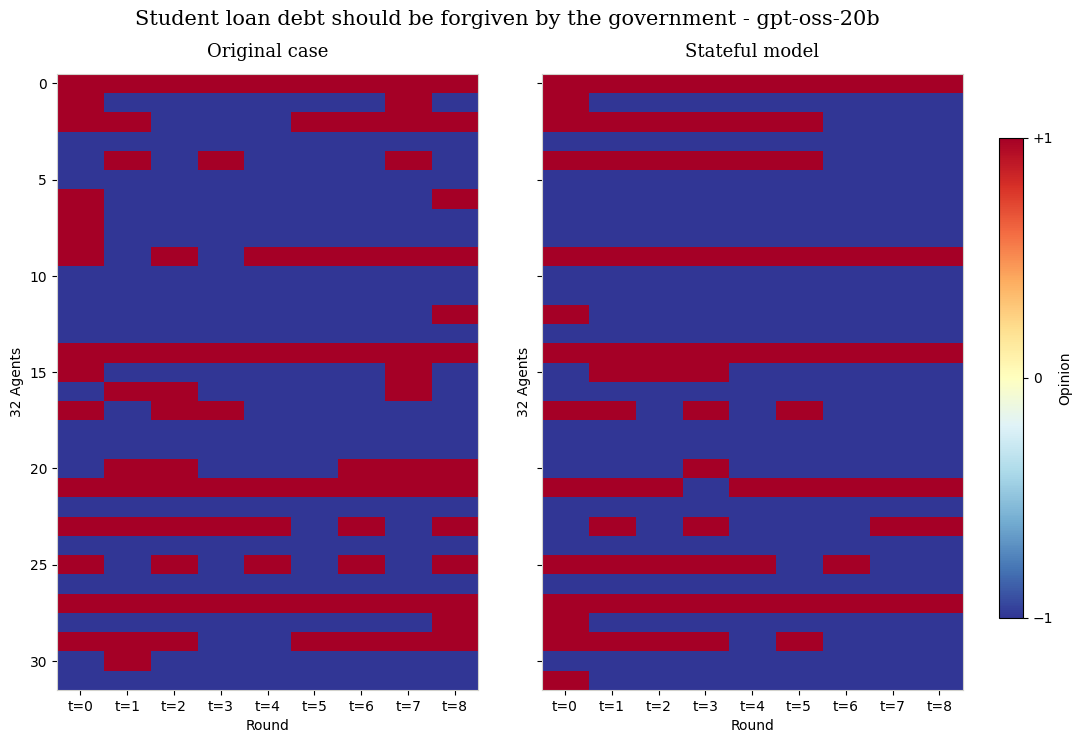

Figure saved to: /Users/leo/Documents/github/physics-of-agents/figures/hitemp_original_vs_stateful_gpt-oss-20b.png


In [83]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

original = hitemp_original
stateful = hitemp_stateful

results = [
    ("Original case", original),
    ("Stateful model", stateful),
]

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

fig.subplots_adjust(
    right=0.88,
    wspace=0.15
)

for ax, (label, r) in zip(axes, results):

    opinions = np.asarray(r["spins_history"])

    # Opinions shape: (rounds, agents)
    T, N = opinions.shape

    # Agents x rounds
    data = opinions.T

    im = ax.imshow(
        data,
        cmap="RdYlBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto",
        interpolation="nearest",
        rasterized=True
    )

    # X axis
    ax.set_xticks(
        range(T),
        [f"t={t}" for t in range(T)]
    )

    ax.set_xlabel("Round")
    ax.set_ylabel(f"{N} Agents")

    ax.set_title(
        label,
        fontsize=13,
        family="serif",
        pad=12
    )

    # Borders
    for s in ax.spines.values():
        s.set_color("#d2d2cc")

# --------------------------------------------------
# Colorbar
# --------------------------------------------------

cbar_ax = fig.add_axes([0.91, 0.2, 0.02, 0.6])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label("Opinion")

cbar.set_ticks([-1, 0, 1])
cbar.set_ticklabels(["−1", "0", "+1"])

# --------------------------------------------------
# Figure title
# --------------------------------------------------

fig.suptitle(
    f"{original['statement']} - {model}",
    fontsize=15,
    family="serif",
    y=0.96
)

plt.show()

# --------------------------------------------------
# Save as PDF
# --------------------------------------------------

output_path = Path(f"../figures/hitemp_original_vs_stateful_{model}.png")


fig.savefig(
    output_path,
    format="png",
    bbox_inches="tight",
    dpi=300
)

print(f"Figure saved to: {output_path.resolve()}")

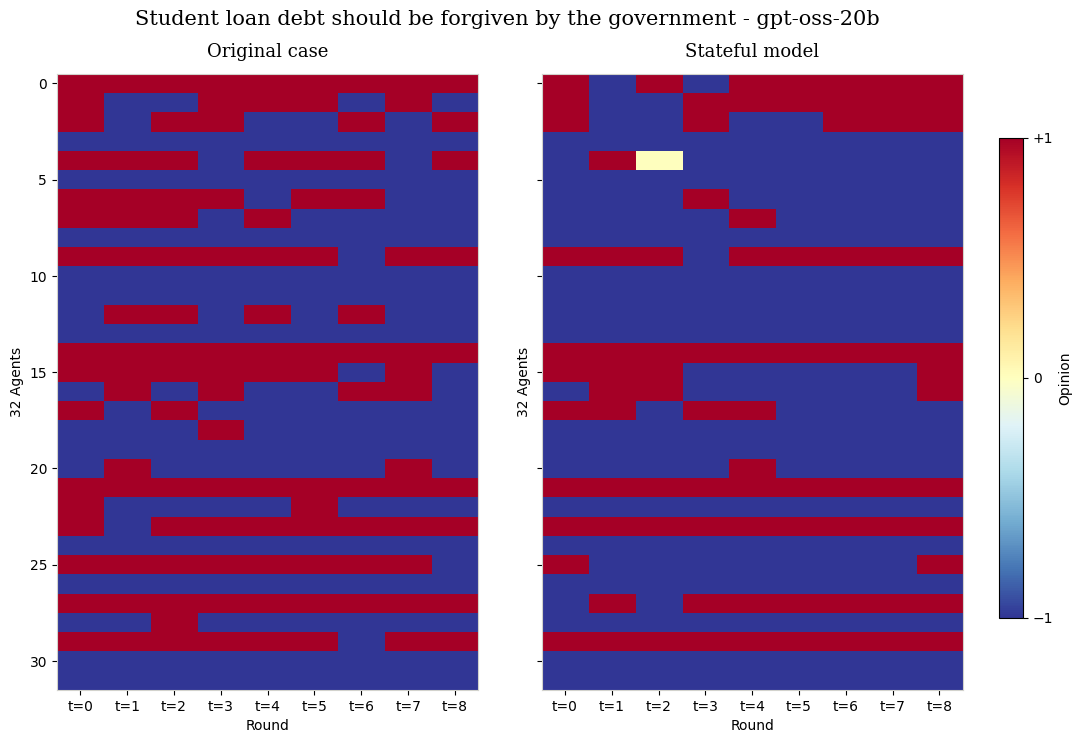

Figure saved to: /Users/leo/Documents/github/physics-of-agents/figures/lowtemp_original_vs_stateful_gpt-oss-20b.png


In [84]:
original = lowtemp_original
stateful = lowtemp_stateful

results = [
    ("Original case", original),
    ("Stateful model", stateful),
]

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

fig.subplots_adjust(
    right=0.88,
    wspace=0.15
)

for ax, (label, r) in zip(axes, results):

    opinions = np.asarray(r["spins_history"])

    # Opinions shape: (rounds, agents)
    T, N = opinions.shape

    # Agents x rounds
    data = opinions.T

    im = ax.imshow(
        data,
        cmap="RdYlBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto",
        interpolation="nearest",
        rasterized=True
    )

    # X axis
    ax.set_xticks(
        range(T),
        [f"t={t}" for t in range(T)]
    )

    ax.set_xlabel("Round")
    ax.set_ylabel(f"{N} Agents")

    ax.set_title(
        label,
        fontsize=13,
        family="serif",
        pad=12
    )

    # Borders
    for s in ax.spines.values():
        s.set_color("#d2d2cc")

# --------------------------------------------------
# Colorbar
# --------------------------------------------------

cbar_ax = fig.add_axes([0.91, 0.2, 0.02, 0.6])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label("Opinion")

cbar.set_ticks([-1, 0, 1])
cbar.set_ticklabels(["−1", "0", "+1"])

# --------------------------------------------------
# Figure title
# --------------------------------------------------

fig.suptitle(
    f"{original['statement']} - {model}",
    fontsize=15,
    family="serif",
    y=0.96
)

plt.show()

# --------------------------------------------------
# Save as PDF
# --------------------------------------------------

output_path = Path(f"../figures/lowtemp_original_vs_stateful_{model}.png")


fig.savefig(
    output_path,
    format="png",
    bbox_inches="tight",
    dpi=300
)

print(f"Figure saved to: {output_path.resolve()}")

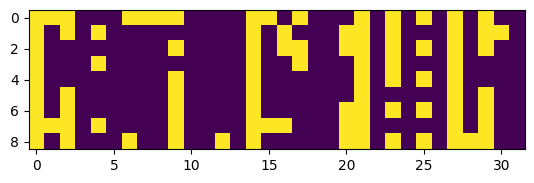

In [85]:
# print stateful spins history

plt.imshow(hitemp_original["spins_history"])

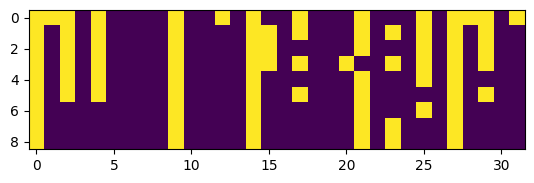

In [86]:
# print stateful spins history

plt.imshow(hitemp_stateful["spins_history"])